# TFT - attention

Encoder attention from the test forward pass. For each test day, decoder step and head, the encoder weights are rescaled so they sum to 1 and then multiplied by the window length E. Each figure averages the five seeds, the 364 test days and the attention heads.

A row is one hour of the forecast day, 00:00 at the top and 23:00 at the bottom. A column is one hour of history, and position −1 is 23:00 on D−1. The windows were chosen separately, so the figures are read for the shape inside each window. Each heatmap has its own colour scale.

A cell above 1 means that hour of history receives more than an equal share of the encoder attention for that forecast hour. Rescaling to the encoder leaves out the attention that stays on the known future inputs, and after that step every row averages to 1.

In [ ]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent.parent))

from src.utils.tft.attention import encoder_attention, plot_attention_heatmap

attention = {step: encoder_attention(step) for step in ("d1", "d2", "d3")}

## d1 - 72 h

The dashed lines mark the starts of D−2 and D−1. The oldest hours of D−3 stay dark, and the weight rises toward the recent evening. The column near 20:00 of D−1 is the brightest and stays bright for the whole forecast day.

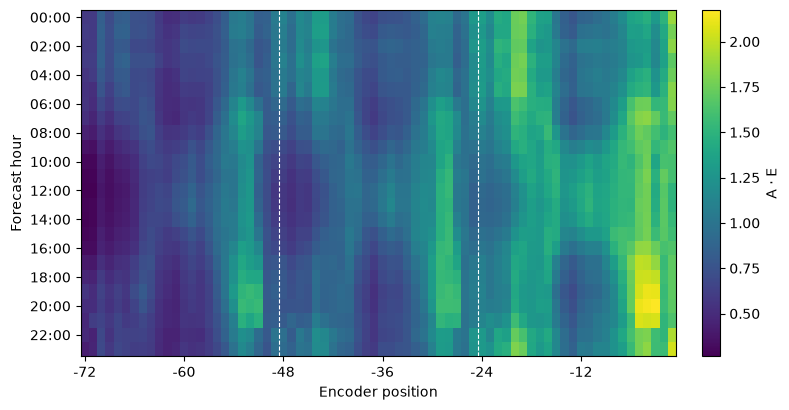

In [ ]:
plot_attention_heatmap(attention["d1"])

## d2 - 48 h

The dashed line marks the start of D-1, and that day is brighter than D-2. Most forecast hours share a band around 09:00 of D-1. The evening forecast hours add bright spots near 19:00 of both D-2 and D-1.

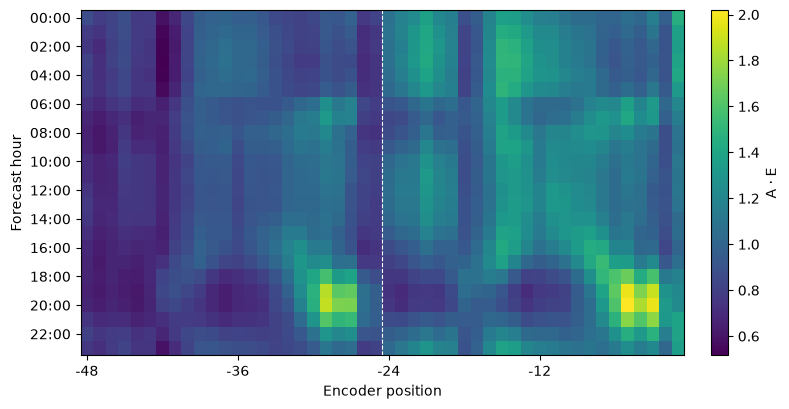

In [ ]:
plot_attention_heatmap(attention["d2"])

## d3 - 24 h

The window is a single day, so the columns run from 00:00 to 23:00 of D-1. The column at 10:00 is bright through the middle of the forecast day. The last forecast hours shift weight toward 23:00, and 00:00 stays the darkest column.

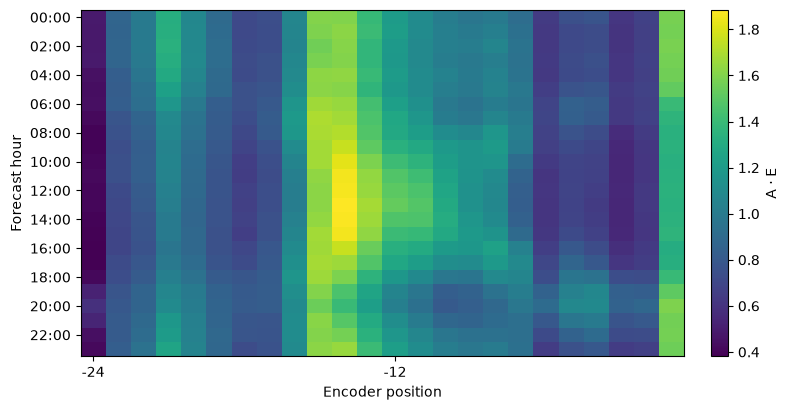

In [ ]:
plot_attention_heatmap(attention["d3"])

## Conclusions

In every window the brighter columns sit on the most recent day, and the older hours fall below a uniform share. The bands are mostly vertical, so most forecast hours look at the same hours of history. The evening of the forecast day is the part that breaks the pattern, especially on d2 and at 23:00 on d3.

On d1 that shared column is the recent evening, near 20:00. On d3 it is late morning, near 10:00. The same number on the colour scale is a smaller slice of the encoder when the window holds 72 hours than when it holds 24, so the three figures are compared by shape.